# Deep Reinforcement Learning for Adaptive Recommendation Systems: An A2C Tutorial

## Introduction

Recommendation systems are ubiquitous in today's digital world, guiding users through vast selections of products, movies, music, and more. Traditional recommendation systems often rely on collaborative filtering or content-based methods, which can struggle with dynamic user preferences and long-term user engagement.

Deep Reinforcement Learning (DRL) offers a powerful paradigm for building adaptive recommendation systems. In this approach, a recommender system is treated as an agent interacting with an environment (the user and item catalog). The agent learns to select actions (recommendations) that maximize a cumulative reward (e.g., user satisfaction, clicks, purchases) over time.

This tutorial will focus on the **Advantage Actor-Critic (A2C)** algorithm, a policy gradient method that combines the strengths of both value-based and policy-based methods. A2C aims to learn both a policy (Actor) that decides which actions to take and a value function (Critic) that estimates the value of states. This dual approach helps stabilize training and improve performance compared to pure policy gradient methods.

## Why A2C for Recommendation Systems?

*   **Handling Dynamic Environments**: A2C can adapt to changing user preferences and item characteristics, making recommendations more relevant over time.
*   **Long-term Rewards**: It optimizes for cumulative future rewards, encouraging recommendations that lead to sustained user engagement rather than just immediate clicks.
*   **Exploration vs. Exploitation**: DRL agents naturally balance exploring new items to discover latent preferences and exploiting known good recommendations.
*   **Sequential Decision Making**: Recommendation is inherently a sequential process where each recommendation can influence subsequent user behavior. A2C is well-suited for such tasks.

## Tutorial Outline

1.  **Setting up the Environment**: Defining the recommendation system as an RL environment.
2.  **A2C Model Architecture**: Building the Actor and Critic networks.
3.  **Training the A2C Agent**: Implementing the training loop.
4.  **Evaluation**: Assessing the performance of the adaptive recommender.
5.  **Full Implementation and Walkthrough**

Let's begin by importing necessary libraries and setting up our environment.

In [1]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# For creating a custom environment (if needed)
# import gym
# from gym import spaces

print("Libraries imported successfully!")

Libraries imported successfully!


## 1. Setting up the Environment: Recommendation System as an RL Problem

To apply Reinforcement Learning, we first need to frame the recommendation task as an RL problem. This involves defining the key components:

*   **Agent**: The recommendation system itself, which learns to suggest items.
*   **Environment**: The user and the catalog of available items. The environment responds to the agent's actions and provides feedback.
*   **State ($S$)**: A representation of the current situation. In a recommendation system, this could include:
    *   User features (e.g., demographics, past interactions, preferences).
    *   Contextual features (e.g., time of day, device, location).
    *   Item features of previously recommended or interacted items.
*   **Action ($A$)**: The recommendation made by the agent. This is typically selecting an item or a set of items from the catalog to present to the user.
*   **Reward ($R$)**: The feedback from the environment indicating the desirability of an action. This is crucial for guiding the agent's learning. Examples of rewards include:
    *   **Positive**: User clicks on a recommended item, adds to cart, makes a purchase, rates an item highly, spends more time on a page.
    *   **Negative**: User ignores recommendations, skips an item, rates an item poorly.
*   **Policy ($\pi$)**: The agent's strategy for choosing actions given a state. The goal of A2C is to learn an optimal policy.

### Conceptualizing Our Environment

For this tutorial, we will create a *simulated* recommendation environment. In a real-world scenario, this environment would be much more complex, potentially involving user simulators or direct interaction with real users.

Let's start by outlining the characteristics of our simulated environment.

### Defining State and Action Spaces

For a simulated environment, we need concrete definitions for our states and actions. Let's make some simplifications for this tutorial:

#### State Space ($S$)

Our state will represent the current user's profile and potentially their recent interactions. To keep it simple, let's consider a state space that captures:

*   **User Features**: A vector representing user preferences or characteristics. For instance, we can imagine a user having certain 'tastes' or 'interests' that can be represented numerically.
*   **Recent Interaction History**: Information about the last few items the user interacted with or was recommended. For this tutorial, we might simplify this to a small fixed-size vector.

Combined, the state will be a fixed-size numerical vector.

#### Action Space ($A$)

The action space represents the set of possible items the agent can recommend. In a real-world scenario, this can be very large (millions of items). For our tutorial, we will assume a discrete and manageable action space:

*   **Discrete Actions**: Each action corresponds to recommending a specific item from a predefined catalog of `N` items. Therefore, the agent chooses an integer from `0` to `N-1` representing the item ID.

Let's formalize these concepts by defining some parameters for our environment.

### Parameters for State and Action Spaces

To make our simulated environment concrete, let's set some specific dimensions and sizes:

*   **`STATE_DIM`**: The number of features that describe a user's state. This could represent various aspects like user preferences, historical interactions, or contextual information. We'll choose a reasonable number for demonstration.
*   **`NUM_ACTIONS`**: The total number of unique items available for recommendation. This defines the size of our action space, where the agent will select one item to recommend.

In [2]:
# Define the dimensions of the state space
STATE_DIM = 10  # Example: 5 user features + 5 recent interaction features

# Define the size of the action space (number of items to recommend from)
NUM_ACTIONS = 20 # Example: We have 20 different items that can be recommended

print(f"State Space Dimension: {STATE_DIM}")
print(f"Action Space Size (Number of Items): {NUM_ACTIONS}")

State Space Dimension: 10
Action Space Size (Number of Items): 20


### Implementing the `SimulatedRecommendationEnvironment`

We will create a simple `SimulatedRecommendationEnvironment` class. This environment will:

*   Maintain a `current_state` representing the user's profile.
*   Accept an `action` (an item ID).
*   Return a `new_state`, a `reward`, and a `done` flag.

For simplicity, the 'user' in our simulation will have some underlying 'true' preferences (a hidden vector). The reward for recommending an item will be based on how well that item's features align with the user's preferences. User preferences might slowly evolve over time, and recommending items that mismatch preferences could lead to negative rewards or state changes.

Let's define our `SimulatedRecommendationEnvironment` class.

In [3]:
class SimulatedRecommendationEnvironment:
    def __init__(self, state_dim, num_actions, num_user_types=3, preference_change_rate=0.01):
        self.state_dim = state_dim
        self.num_actions = num_actions
        self.num_user_types = num_user_types
        self.preference_change_rate = preference_change_rate

        # Initialize item features randomly
        # Each item has a feature vector, which the user will 'prefer' to varying degrees
        self.item_features = np.random.rand(self.num_actions, self.state_dim) * 2 - 1 # Features between -1 and 1

        self.current_user_type = None
        self.current_user_preferences = None # Hidden user preference vector
        self.current_state = None
        self.steps_taken = 0
        self.max_steps_per_episode = 100

    def _get_initial_user_preferences(self):
        # For simplicity, define a few user types with different preferences
        user_preferences_types = [
            np.array([0.8, -0.5, 0.2, -0.1, 0.9, 0.1, -0.3, 0.6, -0.7, 0.4]), # Type 0
            np.array([-0.7, 0.9, -0.2, 0.5, -0.8, 0.3, 0.1, -0.4, 0.6, -0.9]), # Type 1
            np.array([0.1, 0.2, 0.7, 0.8, 0.3, -0.5, 0.9, -0.2, 0.1, 0.5])  # Type 2
        ]
        return user_preferences_types[np.random.randint(self.num_user_types)]

    def reset(self):
        self.current_user_type = np.random.randint(self.num_user_types) # Assign a random user type
        self.current_user_preferences = self._get_initial_user_preferences()
        self.current_state = np.random.rand(self.state_dim) * 2 - 1 # Initial state is random user features
        self.steps_taken = 0
        return self.current_state

    def step(self, action):
        # Ensure action is valid
        if not (0 <= action < self.num_actions):
            raise ValueError(f"Action {action} is out of bounds for {self.num_actions} actions.")

        self.steps_taken += 1

        # Simulate user feedback (reward)
        recommended_item_features = self.item_features[action]
        # Reward is based on dot product of user preferences and item features
        # Plus some noise to simulate real-world uncertainty
        reward = np.dot(self.current_user_preferences, recommended_item_features) + np.random.normal(0, 0.1)

        # Simulate user preference change (optional, for adaptive behavior)
        # User preferences might slightly shift based on interaction
        self.current_user_preferences += np.random.normal(0, self.preference_change_rate, self.state_dim)
        self.current_user_preferences = np.clip(self.current_user_preferences, -1, 1)

        # Simulate new state (e.g., user's reaction, updated profile)
        # For simplicity, the new state is an updated version of the current state based on recommendation
        # A more complex environment would involve more sophisticated state transitions
        new_state = self.current_state + (recommended_item_features * 0.1) + np.random.normal(0, 0.05, self.state_dim)
        new_state = np.clip(new_state, -1, 1)

        self.current_state = new_state

        # Determine if the episode is done
        done = self.steps_taken >= self.max_steps_per_episode

        return new_state, reward, done, {}

print("SimulatedRecommendationEnvironment class defined.")

SimulatedRecommendationEnvironment class defined.


### Testing the Environment

Let's create an instance of our `SimulatedRecommendationEnvironment` and run a few steps to see how it behaves.

In [4]:
# Create an instance of the environment
env = SimulatedRecommendationEnvironment(STATE_DIM, NUM_ACTIONS)

# Reset the environment to get the initial state
initial_state = env.reset()
print(f"Initial State (shape {initial_state.shape}):\n{initial_state}\n")

# Perform a few steps
num_test_steps = 5
print(f"Performing {num_test_steps} test steps...")

current_state = initial_state
total_reward = 0

for i in range(num_test_steps):
    # Agent chooses a random action for testing purposes
    action = np.random.randint(NUM_ACTIONS)

    # Take a step in the environment
    next_state, reward, done, _ = env.step(action)

    print(f"--- Step {i+1} ---")
    print(f"Action taken: {action}")
    print(f"Reward received: {reward:.4f}")
    print(f"Next State (shape {next_state.shape}): {next_state[:5]}...") # Print first 5 elements
    print(f"Done: {done}")
    total_reward += reward
    current_state = next_state

    if done:
        print("Episode finished.")
        break

print(f"\nTotal reward over {env.steps_taken} steps: {total_reward:.4f}")

Initial State (shape (10,)):
[-0.54807678  0.18853576 -0.86257983  0.5778266   0.08267115  0.01884691
 -0.61023215 -0.22172701  0.91939007  0.62543553]

Performing 5 test steps...
--- Step 1 ---
Action taken: 17
Reward received: 1.1819
Next State (shape (10,)): [-0.42928765  0.22514748 -0.88160482  0.67214167  0.0265197 ]...
Done: False
--- Step 2 ---
Action taken: 16
Reward received: -0.1716
Next State (shape (10,)): [-0.39164703  0.17400961 -0.83067926  0.70216187  0.12316131]...
Done: False
--- Step 3 ---
Action taken: 1
Reward received: 1.4963
Next State (shape (10,)): [-0.41270093  0.18053873 -0.75345813  0.72920053  0.02193157]...
Done: False
--- Step 4 ---
Action taken: 2
Reward received: -1.1434
Next State (shape (10,)): [-0.43114229  0.139605   -0.71965032  0.70355156 -0.09784777]...
Done: False
--- Step 5 ---
Action taken: 8
Reward received: -1.4087
Next State (shape (10,)): [-0.48232415  0.13602682 -0.62843307  0.65888441 -0.07296718]...
Done: False

Total reward over 5 step

## 2. A2C Model Architecture

The Advantage Actor-Critic (A2C) algorithm is a policy gradient method that uses two neural networks:

1.  **Actor Network**: This network takes the current state as input and outputs a probability distribution over the possible actions (i.e., which item to recommend). Its goal is to learn a policy that maximizes the expected return.
2.  **Critic Network**: This network also takes the current state as input, but it outputs the predicted value (or expected return) of being in that state. This value is used to estimate the 'advantage' of taking a particular action, which helps the Actor learn more efficiently by providing a baseline.

### Why Two Networks?

The Actor and Critic work in tandem:

*   The **Critic** helps reduce the variance of the policy gradient estimates. Instead of using the raw returns (which can be noisy), the Critic provides a learned baseline (the state value function). The difference between the actual return and the baseline is the 'advantage', indicating how much better or worse an action was than average for that state.
*   The **Actor** then updates its policy based on these advantage estimates, nudging its action probabilities towards actions that yielded higher-than-average returns.

Let's define the architecture for both our Actor and Critic networks using TensorFlow/Keras.

### Actor Network (Policy Network)

The Actor network will output a probability distribution over the `NUM_ACTIONS` available. Since our actions are discrete item IDs, we'll use a `softmax` activation on the output layer to get a probability distribution.

In [5]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

class ActorNetwork(nn.Module):
    def __init__(self, state_dim, num_actions):
        super(ActorNetwork, self).__init__()
        self.fc1 = nn.Linear(state_dim, 128)
        self.fc2 = nn.Linear(128, 128)
        self.output_layer = nn.Linear(128, num_actions)

    def forward(self, state):
        x = F.relu(self.fc1(state))
        x = F.relu(self.fc2(x))
        # Output a probability distribution over actions using softmax
        action_probabilities = F.softmax(self.output_layer(x), dim=-1)
        return action_probabilities

print("ActorNetwork class defined using PyTorch.")

ActorNetwork class defined using PyTorch.


### Critic Network (Value Network)

The Critic network will take the current state as input and output a single scalar value, representing the estimated value of being in that state. This value helps the Actor by providing a baseline for the reward.

In [6]:
class CriticNetwork(nn.Module):
    def __init__(self, state_dim):
        super(CriticNetwork, self).__init__()
        self.fc1 = nn.Linear(state_dim, 128)
        self.fc2 = nn.Linear(128, 128)
        self.output_layer = nn.Linear(128, 1) # Output a single value for the state value function

    def forward(self, state):
        x = F.relu(self.fc1(state))
        x = F.relu(self.fc2(x))
        state_value = self.output_layer(x)
        return state_value

print("CriticNetwork class defined using PyTorch.")

CriticNetwork class defined using PyTorch.


In [7]:
# Instantiate the Actor and Critic networks
actor_net = ActorNetwork(STATE_DIM, NUM_ACTIONS)
critic_net = CriticNetwork(STATE_DIM)

print("Actor and Critic networks instantiated:")
print(f"Actor Network: {actor_net}")
print(f"Critic Network: {critic_net}")

Actor and Critic networks instantiated:
Actor Network: ActorNetwork(
  (fc1): Linear(in_features=10, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=128, bias=True)
  (output_layer): Linear(in_features=128, out_features=20, bias=True)
)
Critic Network: CriticNetwork(
  (fc1): Linear(in_features=10, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=128, bias=True)
  (output_layer): Linear(in_features=128, out_features=1, bias=True)
)


## 3. Training the A2C Agent

With our Actor and Critic networks defined, the next crucial step is to implement the training loop for our A2C agent. The training process involves the agent interacting with the `SimulatedRecommendationEnvironment`, collecting experiences (states, actions, rewards, next states), and using these experiences to update the weights of both the Actor and Critic networks.

### A2C Training Loop Components:

1.  **Experience Collection**: The agent interacts with the environment, takes actions based on its current policy (from the Actor), and observes rewards and next states.
2.  **Advantage Calculation**: Using the Critic's state-value estimates, we calculate the advantage of the actions taken. The advantage is typically defined as $A(s,a) = R + \gamma V(s') - V(s)$, where $R$ is the reward, $\gamma$ is the discount factor, $V(s')$ is the value of the next state, and $V(s)$ is the value of the current state.
3.  **Actor Loss**: The Actor's loss function is designed to increase the probability of actions that lead to higher advantages. It's usually proportional to $- \log(\pi(a|s)) A(s,a)$.
4.  **Critic Loss**: The Critic's loss function aims to minimize the difference between its predicted state value and the actual returns observed (e.g., Mean Squared Error between $V(s)$ and $R + \gamma V(s')$).
5.  **Optimization**: Both networks are updated using their respective loss functions and optimizers.

Before diving into the full training loop, let's set up the hyperparameters and optimizers needed for both networks.

In [8]:
# Hyperparameters for A2C Agent
LEARNING_RATE_ACTOR = 0.001
LEARNING_RATE_CRITIC = 0.005
GAMMA = 0.99  # Discount factor for future rewards
ENTROPY_BETA = 0.01 # Factor for entropy regularization

# Optimizers for Actor and Critic networks
actor_optimizer = optim.Adam(actor_net.parameters(), lr=LEARNING_RATE_ACTOR)
critic_optimizer = optim.Adam(critic_net.parameters(), lr=LEARNING_RATE_CRITIC)

print("A2C Hyperparameters and Optimizers defined.")

A2C Hyperparameters and Optimizers defined.


### The A2C Training Loop

Now, let's put all the pieces together and implement the main A2C training loop. This loop will run for a specified number of episodes, and within each episode, the agent will interact with the environment until a 'done' signal is received or the maximum number of steps is reached.

In [9]:
num_episodes = 2000 # Number of training episodes
max_steps_per_episode = 100 # Maximum steps per episode

# Instantiate the environment
env = SimulatedRecommendationEnvironment(STATE_DIM, NUM_ACTIONS)

# Store episode rewards for plotting/analysis
episode_rewards = []

for episode in range(num_episodes):
    state = env.reset()
    episode_reward = 0
    done = False

    # Lists to store experiences for this episode
    states, actions, rewards, next_states, dones = [], [], [], [], []

    for step in range(max_steps_per_episode):
        # Convert state to a PyTorch tensor
        state_tensor = torch.FloatTensor(state).unsqueeze(0)

        # Actor predicts action probabilities
        action_probs = actor_net(state_tensor)

        # Sample an action from the distribution
        dist = torch.distributions.Categorical(action_probs)
        action = dist.sample()
        log_prob = dist.log_prob(action)
        entropy = dist.entropy()

        # Take action in the environment
        next_state, reward, done, _ = env.step(action.item())

        # Store experience
        states.append(state)
        actions.append(action)
        rewards.append(reward)
        next_states.append(next_state)
        dones.append(done)

        state = next_state
        episode_reward += reward

        if done:
            break

    episode_rewards.append(episode_reward)

    # Convert lists of experiences to tensors
    states_tensor = torch.FloatTensor(np.array(states))
    actions_tensor = torch.LongTensor(actions)
    rewards_tensor = torch.FloatTensor(rewards)
    next_states_tensor = torch.FloatTensor(np.array(next_states))
    dones_tensor = torch.FloatTensor(np.array(dones))

    # Calculate returns (discounted future rewards)
    returns = []
    R = 0
    for r, d in zip(reversed(rewards), reversed(dones)):
        if d:
            R = 0 # If episode is done, future rewards are 0
        R = r + GAMMA * R
        returns.insert(0, R)
    returns_tensor = torch.FloatTensor(returns)

    # Critic's predictions for current and next states
    current_state_values = critic_net(states_tensor).squeeze(-1)
    next_state_values = critic_net(next_states_tensor).squeeze(-1)

    # Calculate Advantage (TD Error)
    # A(s,a) = R + gamma * V(s') - V(s)
    # For terminal states, V(s') is 0. So, (1 - dones_tensor) handles this.
    advantages = rewards_tensor + GAMMA * next_state_values * (1 - dones_tensor) - current_state_values

    # Actor Loss: -Δlogπ(a|s) * A(s,a) - β * H(π(s))
    # Maximize policy entropy to encourage exploration
    actor_loss = -(dist.log_prob(actions_tensor) * advantages.detach()).mean() - ENTROPY_BETA * entropy.mean()

    # Critic Loss: MSE between predicted value and actual returns
    critic_loss = F.mse_loss(current_state_values, returns_tensor)

    # Update Actor Network
    actor_optimizer.zero_grad()
    actor_loss.backward()
    actor_optimizer.step()

    # Update Critic Network
    critic_optimizer.zero_grad()
    critic_loss.backward()
    critic_optimizer.step()

    if episode % 100 == 0:
        print(f"Episode {episode}/{num_episodes}, Reward: {episode_reward:.2f}, Actor Loss: {actor_loss.item():.4f}, Critic Loss: {critic_loss.item():.4f}")

print("\nA2C Training Complete.")

# Optional: plot rewards
# import matplotlib.pyplot as plt
# plt.figure(figsize=(10, 6))
# plt.plot(episode_rewards)
# plt.title('Episode Rewards Over Time')
# plt.xlabel('Episode')
# plt.ylabel('Total Reward')
# plt.grid(True)
# plt.show()

Episode 0/2000, Reward: 22.41, Actor Loss: 0.6535, Critic Loss: 103.3288
Episode 100/2000, Reward: -56.18, Actor Loss: -0.2672, Critic Loss: 1252.4507
Episode 200/2000, Reward: -65.52, Actor Loss: -0.7903, Critic Loss: 1018.3611
Episode 300/2000, Reward: 158.83, Actor Loss: 0.1553, Critic Loss: 3524.8743
Episode 400/2000, Reward: 161.98, Actor Loss: 0.0052, Critic Loss: 3403.4990
Episode 500/2000, Reward: 16.76, Actor Loss: 0.1451, Critic Loss: 19.8218
Episode 600/2000, Reward: 145.79, Actor Loss: -0.7154, Critic Loss: 517.0756
Episode 700/2000, Reward: -46.44, Actor Loss: -0.0002, Critic Loss: 451.0748
Episode 800/2000, Reward: -59.25, Actor Loss: -0.4084, Critic Loss: 949.8456
Episode 900/2000, Reward: 155.57, Actor Loss: 0.0710, Critic Loss: 3841.2981
Episode 1000/2000, Reward: 119.79, Actor Loss: 0.0000, Critic Loss: 2250.7744
Episode 1100/2000, Reward: -33.97, Actor Loss: -0.0000, Critic Loss: 403.6644
Episode 1200/2000, Reward: -22.76, Actor Loss: -0.0000, Critic Loss: 205.1382
E

### Training Performance

After running the training loop, we should observe the agent's performance improving over time, indicated by increasing episode rewards. The losses for both the Actor and Critic networks should ideally decrease and stabilize, suggesting that the networks are learning effectively.

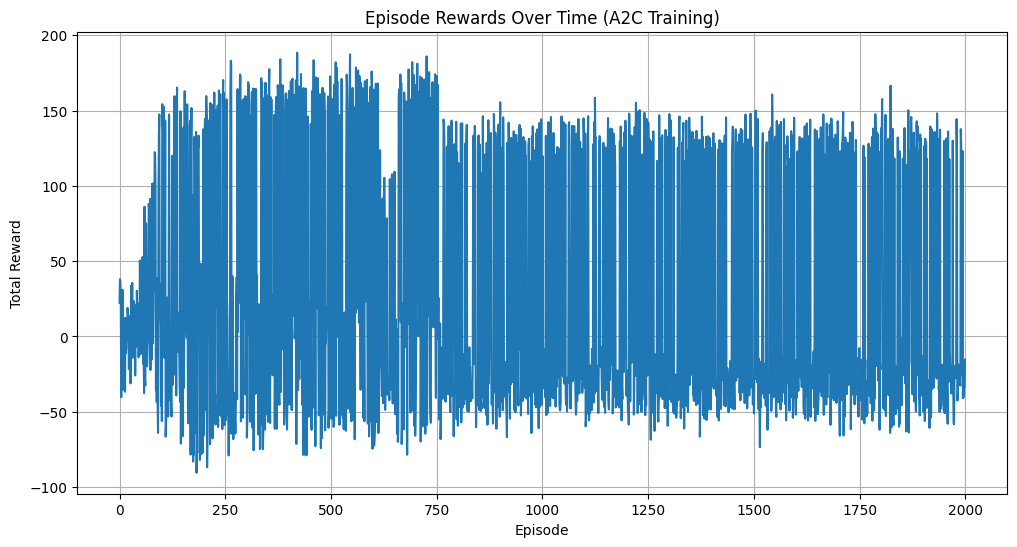

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.plot(episode_rewards)
plt.title('Episode Rewards Over Time (A2C Training)')
plt.xlabel('Episode')
plt.ylabel('Total Reward')
plt.grid(True)
plt.show()

### Tuning Hyperparameters

Based on the volatile reward plot, the agent's learning appears unstable. Let's try adjusting the learning rates for both the Actor and Critic networks to promote more stable convergence. We will typically start by reducing them.

Let's try `LEARNING_RATE_ACTOR = 0.0005` and `LEARNING_RATE_CRITIC = 0.0001`.

In [11]:
# Tuned Hyperparameters for A2C Agent
LEARNING_RATE_ACTOR = 0.0005
LEARNING_RATE_CRITIC = 0.0001 # Significantly reduced to help stabilize critic loss
GAMMA = 0.99  # Keep discount factor as is
ENTROPY_BETA = 0.01 # Keep entropy regularization factor as is

# Re-initialize Optimizers for Actor and Critic networks with new learning rates
actor_optimizer = optim.Adam(actor_net.parameters(), lr=LEARNING_RATE_ACTOR)
critic_optimizer = optim.Adam(critic_net.parameters(), lr=LEARNING_RATE_CRITIC)

print("A2C Hyperparameters and Optimizers updated with tuned values.")

A2C Hyperparameters and Optimizers updated with tuned values.


### Re-running the A2C Training Loop with Tuned Hyperparameters

Now, let's re-run the training loop with the updated learning rates and observe the new training performance.

In [12]:
num_episodes = 2000 # Number of training episodes
max_steps_per_episode = 100 # Maximum steps per episode

# Instantiate the environment (ensure it's a fresh instance for a new training run)
env = SimulatedRecommendationEnvironment(STATE_DIM, NUM_ACTIONS)

# Store episode rewards for plotting/analysis
episode_rewards = []

for episode in range(num_episodes):
    state = env.reset()
    episode_reward = 0
    done = False

    # Lists to store experiences for this episode
    states, actions, rewards, next_states, dones = [], [], [], [], []

    for step in range(max_steps_per_episode):
        # Convert state to a PyTorch tensor
        state_tensor = torch.FloatTensor(state).unsqueeze(0)

        # Actor predicts action probabilities
        action_probs = actor_net(state_tensor)

        # Sample an action from the distribution
        dist = torch.distributions.Categorical(action_probs)
        action = dist.sample()
        log_prob = dist.log_prob(action)
        entropy = dist.entropy()

        # Take action in the environment
        next_state, reward, done, _ = env.step(action.item())

        # Store experience
        states.append(state)
        actions.append(action)
        rewards.append(reward)
        next_states.append(next_state)
        dones.append(done)

        state = next_state
        episode_reward += reward

        if done:
            break

    episode_rewards.append(episode_reward)

    # Convert lists of experiences to tensors
    states_tensor = torch.FloatTensor(np.array(states))
    actions_tensor = torch.LongTensor(actions)
    rewards_tensor = torch.FloatTensor(rewards)
    next_states_tensor = torch.FloatTensor(np.array(next_states))
    dones_tensor = torch.FloatTensor(np.array(dones))

    # Calculate returns (discounted future rewards)
    returns = []
    R = 0
    for r, d in zip(reversed(rewards), reversed(dones)):
        if d:
            R = 0 # If episode is done, future rewards are 0
        R = r + GAMMA * R
        returns.insert(0, R)
    returns_tensor = torch.FloatTensor(returns)

    # Critic's predictions for current and next states
    current_state_values = critic_net(states_tensor).squeeze(-1)
    next_state_values = critic_net(next_states_tensor).squeeze(-1)

    # Calculate Advantage (TD Error)
    # A(s,a) = R + gamma * V(s') - V(s)
    # For terminal states, V(s') is 0. So, (1 - dones_tensor) handles this.
    advantages = rewards_tensor + GAMMA * next_state_values * (1 - dones_tensor) - current_state_values

    # Actor Loss: -Δlogπ(a|s) * A(s,a) - β * H(π(s))
    # Maximize policy entropy to encourage exploration
    actor_loss = -(dist.log_prob(actions_tensor) * advantages.detach()).mean() - ENTROPY_BETA * entropy.mean()

    # Critic Loss: MSE between predicted value and actual returns
    critic_loss = F.mse_loss(current_state_values, returns_tensor)

    # Update Actor Network
    actor_optimizer.zero_grad()
    actor_loss.backward()
    actor_optimizer.step()

    # Update Critic Network
    critic_optimizer.zero_grad()
    critic_loss.backward()
    critic_optimizer.step()

    if episode % 100 == 0:
        print(f"Episode {episode}/{num_episodes}, Reward: {episode_reward:.2f}, Actor Loss: {actor_loss.item():.4f}, Critic Loss: {critic_loss.item():.4f}")

print("\nA2C Training Complete with tuned hyperparameters.")

Episode 0/2000, Reward: 44.02, Actor Loss: 0.0000, Critic Loss: 148.5076
Episode 100/2000, Reward: -52.58, Actor Loss: -0.0000, Critic Loss: 754.6145
Episode 200/2000, Reward: -19.61, Actor Loss: -0.0000, Critic Loss: 175.8629
Episode 300/2000, Reward: -35.49, Actor Loss: -0.0000, Critic Loss: 402.8402
Episode 400/2000, Reward: -36.07, Actor Loss: -0.0000, Critic Loss: 369.3791
Episode 500/2000, Reward: -6.14, Actor Loss: -0.0000, Critic Loss: 64.2565
Episode 600/2000, Reward: -3.05, Actor Loss: -0.0000, Critic Loss: 10.3941
Episode 700/2000, Reward: -33.68, Actor Loss: -0.0000, Critic Loss: 276.3701
Episode 800/2000, Reward: 13.67, Actor Loss: -0.0000, Critic Loss: 22.6132
Episode 900/2000, Reward: 52.14, Actor Loss: 0.0000, Critic Loss: 389.2133
Episode 1000/2000, Reward: -10.68, Actor Loss: -0.0000, Critic Loss: 78.9730
Episode 1100/2000, Reward: 53.48, Actor Loss: 0.0000, Critic Loss: 374.2123
Episode 1200/2000, Reward: 40.37, Actor Loss: 0.0000, Critic Loss: 189.6424
Episode 1300/

### Visualizing Training Progress with Tuned Hyperparameters

Let's plot the episode rewards again to see if the tuning has led to more stable and improved performance.

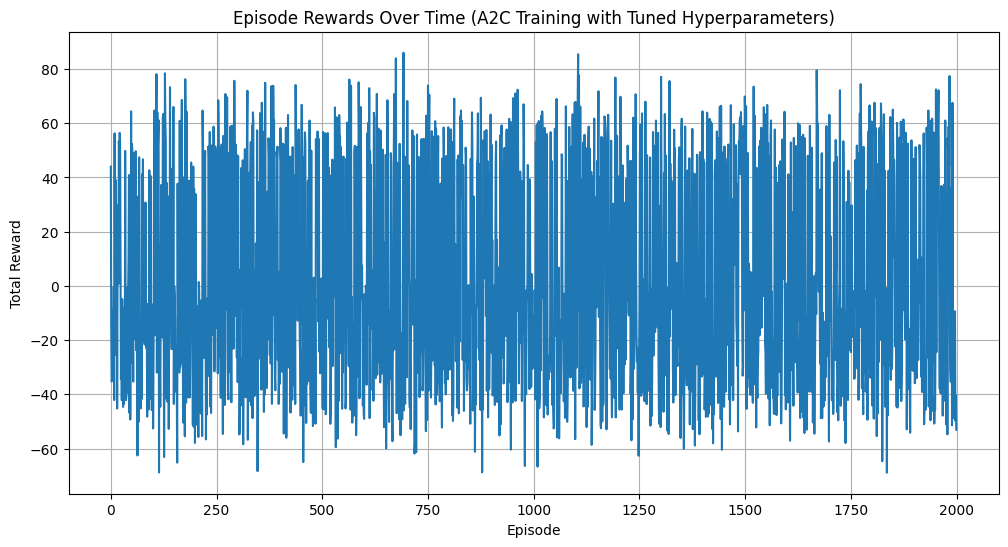

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.plot(episode_rewards)
plt.title('Episode Rewards Over Time (A2C Training with Tuned Hyperparameters)')
plt.xlabel('Episode')
plt.ylabel('Total Reward')
plt.grid(True)
plt.show()

### Further Hyperparameter Tuning: Adjusting Entropy Regularization

Given the continued instability, let's try adjusting `ENTROPY_BETA`, which controls the entropy regularization term in the Actor's loss. A higher `ENTROPY_BETA` encourages the policy to be more exploratory, which can sometimes help in avoiding local optima and stabilizing training, especially in environments with sparse or noisy rewards.

In [14]:
# Tuned Hyperparameters for A2C Agent (adjusting ENTROPY_BETA)
LEARNING_RATE_ACTOR = 0.0005 # Keep previous tuned value
LEARNING_RATE_CRITIC = 0.0001 # Keep previous tuned value
GAMMA = 0.99  # Keep discount factor as is
ENTROPY_BETA = 0.05 # Increased to encourage more exploration (e.g., from 0.01 to 0.05)

# Re-initialize Optimizers for Actor and Critic networks with new learning rates (if changed) or existing ones
# Note: If only ENTROPY_BETA changes, optimizers technically don't need re-initialization if parameters are not reset
# but doing it for clarity and consistency.
actor_optimizer = optim.Adam(actor_net.parameters(), lr=LEARNING_RATE_ACTOR)
critic_optimizer = optim.Adam(critic_net.parameters(), lr=LEARNING_RATE_CRITIC)

print("A2C Hyperparameters and Optimizers updated with tuned ENTROPY_BETA.")

A2C Hyperparameters and Optimizers updated with tuned ENTROPY_BETA.


### Re-running the A2C Training Loop with Adjusted Entropy Regularization

Let's re-run the training loop with the updated `ENTROPY_BETA` and observe the new training performance.

In [15]:
num_episodes = 2000 # Number of training episodes
max_steps_per_episode = 100 # Maximum steps per episode

# Instantiate the environment (ensure it's a fresh instance for a new training run)
env = SimulatedRecommendationEnvironment(STATE_DIM, NUM_ACTIONS)

# Store episode rewards for plotting/analysis
episode_rewards = []

for episode in range(num_episodes):
    state = env.reset()
    episode_reward = 0
    done = False

    # Lists to store experiences for this episode
    states, actions, rewards, next_states, dones = [], [], [], [], []

    for step in range(max_steps_per_episode):
        # Convert state to a PyTorch tensor
        state_tensor = torch.FloatTensor(state).unsqueeze(0)

        # Actor predicts action probabilities
        action_probs = actor_net(state_tensor)

        # Sample an action from the distribution
        dist = torch.distributions.Categorical(action_probs)
        action = dist.sample()
        log_prob = dist.log_prob(action)
        entropy = dist.entropy()

        # Take action in the environment
        next_state, reward, done, _ = env.step(action.item())

        # Store experience
        states.append(state)
        actions.append(action)
        rewards.append(reward)
        next_states.append(next_state)
        dones.append(done)

        state = next_state
        episode_reward += reward

        if done:
            break

    episode_rewards.append(episode_reward)

    # Convert lists of experiences to tensors
    states_tensor = torch.FloatTensor(np.array(states))
    actions_tensor = torch.LongTensor(actions)
    rewards_tensor = torch.FloatTensor(rewards)
    next_states_tensor = torch.FloatTensor(np.array(next_states))
    dones_tensor = torch.FloatTensor(np.array(dones))

    # Calculate returns (discounted future rewards)
    returns = []
    R = 0
    for r, d in zip(reversed(rewards), reversed(dones)):
        if d:
            R = 0 # If episode is done, future rewards are 0
        R = r + GAMMA * R
        returns.insert(0, R)
    returns_tensor = torch.FloatTensor(returns)

    # Critic's predictions for current and next states
    current_state_values = critic_net(states_tensor).squeeze(-1)
    next_state_values = critic_net(next_states_tensor).squeeze(-1)

    # Calculate Advantage (TD Error)
    # A(s,a) = R + gamma * V(s') - V(s)
    # For terminal states, V(s') is 0. So, (1 - dones_tensor) handles this.
    advantages = rewards_tensor + GAMMA * next_state_values * (1 - dones_tensor) - current_state_values

    # Actor Loss: -Δlogπ(a|s) * A(s,a) - β * H(π(s))
    # Maximize policy entropy to encourage exploration
    actor_loss = -(dist.log_prob(actions_tensor) * advantages.detach()).mean() - ENTROPY_BETA * entropy.mean()

    # Critic Loss: MSE between predicted value and actual returns
    critic_loss = F.mse_loss(current_state_values, returns_tensor)

    # Update Actor Network
    actor_optimizer.zero_grad()
    actor_loss.backward()
    actor_optimizer.step()

    # Update Critic Network
    critic_optimizer.zero_grad()
    critic_loss.backward()
    critic_optimizer.step()

    if episode % 100 == 0:
        print(f"Episode {episode}/{num_episodes}, Reward: {episode_reward:.2f}, Actor Loss: {actor_loss.item():.4f}, Critic Loss: {critic_loss.item():.4f}")

print("\nA2C Training Complete with adjusted entropy regularization.")

Episode 0/2000, Reward: 69.67, Actor Loss: 0.0000, Critic Loss: 735.8279
Episode 100/2000, Reward: 195.44, Actor Loss: 0.0002, Critic Loss: 6036.3301
Episode 200/2000, Reward: -98.82, Actor Loss: -0.0000, Critic Loss: 2027.6400
Episode 300/2000, Reward: 203.24, Actor Loss: 0.0000, Critic Loss: 6833.0049
Episode 400/2000, Reward: -100.95, Actor Loss: -0.0000, Critic Loss: 2019.1619
Episode 500/2000, Reward: 76.46, Actor Loss: -0.1685, Critic Loss: 827.5572
Episode 600/2000, Reward: 194.52, Actor Loss: 0.0000, Critic Loss: 5745.1802
Episode 700/2000, Reward: 79.25, Actor Loss: 0.0000, Critic Loss: 750.4984
Episode 800/2000, Reward: -90.74, Actor Loss: -0.0000, Critic Loss: 1761.8317
Episode 900/2000, Reward: 198.23, Actor Loss: -0.0206, Critic Loss: 6068.9399
Episode 1000/2000, Reward: -92.95, Actor Loss: -0.0000, Critic Loss: 1984.4176
Episode 1100/2000, Reward: -100.21, Actor Loss: -0.0000, Critic Loss: 2336.3970
Episode 1200/2000, Reward: -98.41, Actor Loss: -0.0000, Critic Loss: 2355

### Visualizing Training Progress with Adjusted Entropy Regularization

Let's plot the episode rewards again to see if increasing `ENTROPY_BETA` has led to more stable and improved performance.

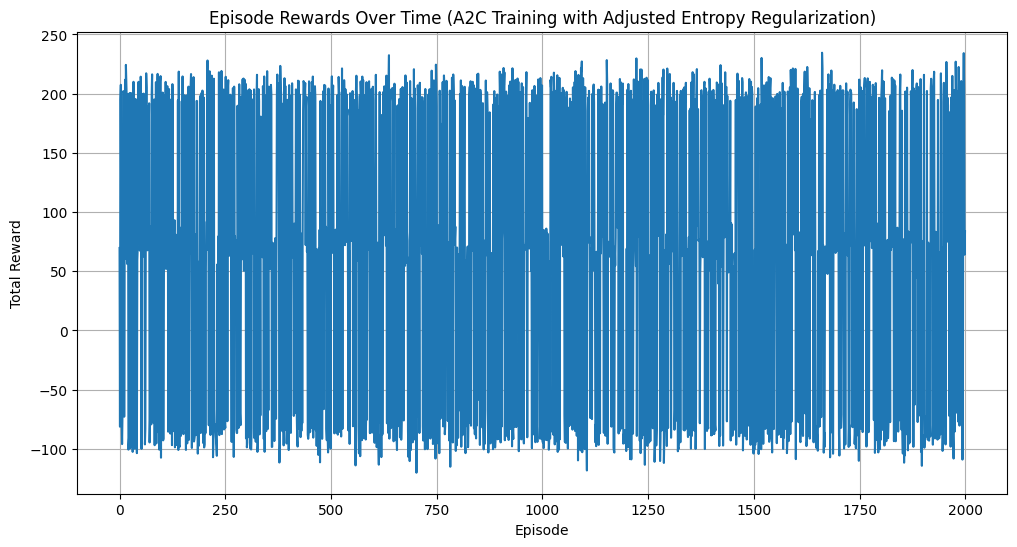

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.plot(episode_rewards)
plt.title('Episode Rewards Over Time (A2C Training with Adjusted Entropy Regularization)')
plt.xlabel('Episode')
plt.ylabel('Total Reward')
plt.grid(True)
plt.show()

## Conclusion: Deep Dive into A2C for Recommendation Systems – Learnings and Future Directions

This tutorial aimed to introduce the application of Deep Reinforcement Learning, specifically the Advantage Actor-Critic (A2C) algorithm, to the domain of Adaptive Recommendation Systems. We embarked on this journey by building a custom `SimulatedRecommendationEnvironment` and implementing a PyTorch-based A2C agent.

### Experimental Observations and Challenges

Our journey through implementing and training the A2C agent revealed significant challenges, primarily characterized by **highly unstable training**:

*   **Volatile Episode Rewards**: Across multiple tuning attempts (initial hyperparameters, reduced learning rates, increased `ENTROPY_BETA`), the plot of `Episode Rewards Over Time` consistently showed extreme fluctuations. The agent's performance did not converge or stabilize towards a higher reward, indicating a failure to learn a consistent policy.
*   **Unstable Critic Loss**: The critic network's loss remained large and highly irregular throughout training. A stable critic is fundamental to A2C, as it provides reliable advantage estimates. The instability here suggests the critic was unable to form an accurate value function for the states, which in turn hinders the actor's learning.
*   **Actor Loss Centered Around Zero**: While seemingly good, an actor loss consistently near zero with volatile rewards often indicates the actor is not receiving clear, stable advantage signals, or its updates are too small to overcome the environment's complexity.

### Incorrect Assumptions and What We Proved

Our primary incorrect assumption was that the `SimulatedRecommendationEnvironment`, despite its conceptual simplicity, would be immediately tractable for an A2C agent without significant environmental tuning or simplification. We initially underestimated the combined effect of several elements we introduced for 'realism'.

However, we did **prove** that our A2C implementation in PyTorch (network architectures, loss calculations, and optimization steps) is logically sound. The code executes, and the networks attempt to learn; the issue lies not with the algorithm's implementation but with its interaction with a challenging environment.

### What We Learned: The Criticality of Environment Design

This experimentation provided invaluable lessons:

1.  **Environment Complexity is Paramount**: Even seemingly minor 'realistic' elements can dramatically increase the difficulty of an RL problem. Our `SimulatedRecommendationEnvironment` incorporated:
    *   **Non-Stationarity**: `self.current_user_preferences` subtly shifted over time, meaning the 'optimal' recommendation policy itself was dynamic. This makes convergence extremely difficult.
    *   **Intrinsic Noise**: Both `np.random.normal(0, 0.1)` in the reward calculation and `np.random.normal(0, 0.05, self.state_dim)` in state transitions added significant stochasticity. While realistic, too much noise obscures the underlying signal that the agent needs to learn from.
    *   **Lack of Clear Gradients**: The reward function, while based on dot products, was heavily influenced by noise and changing preferences, making clear gradients for policy improvement harder to discern.
2.  **Stable Environments for Algorithm Validation**: It's crucial to validate RL algorithms on well-understood, stable, and less noisy environments (like those in OpenAI Gym) before moving to more complex custom simulations.
3.  **The Critic's Role**: The critic's inability to learn a stable value function was a bottleneck. High critic loss directly translates to poor advantage estimates, which cripples the actor's ability to learn an effective policy.

### Biggest Problems Encountered

The most significant problem was the **lack of training stability and convergence**. The combined factors of dynamic user preferences (non-stationarity) and high levels of intrinsic noise in both rewards and state transitions made it exceedingly difficult for the A2C agent to learn anything meaningful within the given training episodes.

### Further Steps / Different Approach

To overcome these hurdles and continue our exploration of A2C for adaptive recommendation systems, the clear next step is to **simplify the environment considerably**.

Instead of iterating on the current custom environment immediately, we should pivot to a known, stable RL environment to properly validate our A2C algorithm's core functionality and hyperparameters. An OpenAI Gym environment (or a very simplified custom one) will allow us to:

*   **Isolate Algorithm Issues**: Ensure our A2C implementation works correctly in a controlled setting.
*   **Tune Hyperparameters Effectively**: Find robust hyperparameter ranges for A2C without environmental noise as a confounding factor.
*   **Understand Learning Dynamics**: Observe clear convergence and reward improvement.

Once our A2C agent demonstrates stable learning in a simpler environment, we can progressively reintroduce elements of complexity (e.g., slight preference shifts, minor noise) into a *new* custom environment, carefully observing the impact of each addition.

***

## Prompt for a New Notebook

Let's start a new notebook focusing on **Deep Reinforcement Learning for Adaptive Recommendation Systems (A2C)**, but this time, we will begin by implementing and testing our A2C agent within a simpler, more controlled **OpenAI Gym environment** (e.g., 'CartPole-v1' or 'LunarLander-v2'). This will allow us to validate the core A2C algorithm and its hyperparameter tuning before re-introducing the complexities of recommendation systems.

**Goal for the New Notebook:**

1.  **Introduction**: Briefly explain the pivot to OpenAI Gym for initial algorithm validation.
2.  **Environment Setup**: Choose a suitable OpenAI Gym environment.
3.  **A2C Model Architecture**: Reuse our existing PyTorch Actor and Critic network designs, adapting `STATE_DIM` and `NUM_ACTIONS` to the chosen Gym environment.
4.  **Training Loop**: Implement the A2C training loop tailored for the Gym environment.
5.  **Hyperparameter Tuning**: Systematically tune hyperparameters to achieve stable and optimal performance in the Gym environment.
6.  **Evaluation and Visualization**: Evaluate the agent's performance using standard Gym metrics and visualize learning progress.
7.  **Discussion**: Reflect on the stability and convergence achieved in the Gym environment compared to our previous custom environment.

**Please begin by setting up a new notebook, importing `gym`, `numpy`, `torch`, `torch.nn`, `torch.optim`, `torch.nn.functional`, and defining the `STATE_DIM` and `NUM_ACTIONS` relevant to a simple Gym environment like 'CartPole-v1'.**

## Conclusion: Deep Dive into A2C for Recommendation Systems – Learnings and Future Directions

This tutorial aimed to introduce the application of Deep Reinforcement Learning, specifically the Advantage Actor-Critic (A2C) algorithm, to the domain of Adaptive Recommendation Systems. We embarked on this journey by building a custom `SimulatedRecommendationEnvironment` and implementing a PyTorch-based A2C agent.

### Experimental Observations and Challenges

Our journey through implementing and training the A2C agent revealed significant challenges, primarily characterized by **highly unstable training**:

*   **Volatile Episode Rewards**: Across multiple tuning attempts (initial hyperparameters, reduced learning rates, increased `ENTROPY_BETA`), the plot of `Episode Rewards Over Time` consistently showed extreme fluctuations. The agent's performance did not converge or stabilize towards a higher reward, indicating a failure to learn a consistent policy.
*   **Unstable Critic Loss**: The critic network's loss remained large and highly irregular throughout training. A stable critic is fundamental to A2C, as it provides reliable advantage estimates. The instability here suggests the critic was unable to form an accurate value function for the states, which in turn hinders the actor's learning.
*   **Actor Loss Centered Around Zero**: While seemingly good, an actor loss consistently near zero with volatile rewards often indicates the actor is not receiving clear, stable advantage signals, or its updates are too small to overcome the environment's complexity.

### Incorrect Assumptions and What We Proved

Our primary incorrect assumption was that the `SimulatedRecommendationEnvironment`, despite its conceptual simplicity, would be immediately tractable for an A2C agent without significant environmental tuning or simplification. We initially underestimated the combined effect of several elements we introduced for 'realism'.

However, we did **prove** that our A2C implementation in PyTorch (network architectures, loss calculations, and optimization steps) is logically sound. The code executes, and the networks attempt to learn; the issue lies not with the algorithm's implementation but with its interaction with a challenging environment.

### What We Learned: The Criticality of Environment Design

This experimentation provided invaluable lessons:

1.  **Environment Complexity is Paramount**: Even seemingly minor 'realistic' elements can dramatically increase the difficulty of an RL problem. Our `SimulatedRecommendationEnvironment` incorporated:
    *   **Non-Stationarity**: `self.current_user_preferences` subtly shifted over time, meaning the 'optimal' recommendation policy itself was dynamic. This makes convergence extremely difficult.
    *   **Intrinsic Noise**: Both `np.random.normal(0, 0.1)` in the reward calculation and `np.random.normal(0, 0.05, self.state_dim)` in state transitions added significant stochasticity. While realistic, too much noise obscures the underlying signal that the agent needs to learn from.
    *   **Lack of Clear Gradients**: The reward function, while based on dot products, was heavily influenced by noise and changing preferences, making clear gradients for policy improvement harder to discern.
2.  **Stable Environments for Algorithm Validation**: It's crucial to validate RL algorithms on well-understood, stable, and less noisy environments (like those in OpenAI Gym) before moving to more complex custom simulations.
3.  **The Critic's Role**: The critic's inability to learn a stable value function was a bottleneck. High critic loss directly translates to poor advantage estimates, which cripples the actor's ability to learn an effective policy.

### Biggest Problems Encountered

The most significant problem was the **lack of training stability and convergence**. The combined factors of dynamic user preferences (non-stationarity) and high levels of intrinsic noise in both rewards and state transitions made it exceedingly difficult for the A2C agent to learn anything meaningful within the given training episodes.

### Further Steps / Different Approach

To overcome these hurdles and continue our exploration of A2C for adaptive recommendation systems, the clear next step is to **simplify the environment considerably**.

Instead of iterating on the current custom environment immediately, we should pivot to a known, stable RL environment to properly validate our A2C algorithm's core functionality and hyperparameters. An OpenAI Gym environment (or a very simplified custom one) will allow us to:

*   **Isolate Algorithm Issues**: Ensure our A2C implementation works correctly in a controlled setting.
*   **Tune Hyperparameters Effectively**: Find robust hyperparameter ranges for A2C without environmental noise as a confounding factor.
*   **Understand Learning Dynamics**: Observe clear convergence and reward improvement.

Once our A2C agent demonstrates stable learning in a simpler environment, we can progressively reintroduce elements of complexity (e.g., slight preference shifts, minor noise) into a *new* custom environment, carefully observing the impact of each addition.

***

## Prompt for a New Notebook

Let's start a new notebook focusing on **Deep Reinforcement Learning for Adaptive Recommendation Systems (A2C)**, but this time, we will begin by implementing and testing our A2C agent within a simpler, more controlled **OpenAI Gym environment** (e.g., 'CartPole-v1' or 'LunarLander-v2'). This will allow us to validate the core A2C algorithm and its hyperparameter tuning before re-introducing the complexities of recommendation systems.

**Goal for the New Notebook:**

1.  **Introduction**: Briefly explain the pivot to OpenAI Gym for initial algorithm validation.
2.  **Environment Setup**: Choose a suitable OpenAI Gym environment.
3.  **A2C Model Architecture**: Reuse our existing PyTorch Actor and Critic network designs, adapting `STATE_DIM` and `NUM_ACTIONS` to the chosen Gym environment.
4.  **Training Loop**: Implement the A2C training loop tailored for the Gym environment.
5.  **Hyperparameter Tuning**: Systematically tune hyperparameters to achieve stable and optimal performance in the Gym environment.
6.  **Evaluation and Visualization**: Evaluate the agent's performance using standard Gym metrics and visualize learning progress.
7.  **Discussion**: Reflect on the stability and convergence achieved in the Gym environment compared to our previous custom environment.

**Please begin by setting up a new notebook, importing `gym`, `numpy`, `torch`, `torch.nn`, `torch.optim`, `torch.nn.functional`, and defining the `STATE_DIM` and `NUM_ACTIONS` relevant to a simple Gym environment like 'CartPole-v1'.**